In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<center><h1> Traffic Sign Detection with YOLO</h1></center>

**IAT 360 Group 17:** Manroop Sandhu, Sean Penner, Vanshdeep Sidhu <br>
**GitHub:** [link]

# Abstract

### Purpose


### Summary


### Conclusions
[do when done?]

# Table of Contents
  - [Intro: Traffic Sign Detection on the LISA dataset](#Intro:-Traffic-Sign-Detection-on-the-LISA-dataset)
  - [Machine Learning Process Overview](#Machine-Learning-Process-Overview)
  - [Load the Dataset](#Load-the-Dataset)
  - [Checking the Dataset](#Checking-the-Dataset)
  - [The Baseline Model](#The-Baseline-Model)
    - [The Loss Curve](#The-Loss-Curve)
    - [The Confusion Matrix](#The-Confusion-Matrix)
    - [Precision, Recall, mAP](#Precision,-Recall,-mAP)
  - [Hyperparameter Tuning](#Hyperparameter-Tuning)
  - [Final Model](#Final-Model)
  - [Setting up for Our Photos](#Setting-up-for-Our-Photos)

## Intro: Traffic Sign Detection on the LISA dataset
We're going to use the LISA Traffic Sign Dataset from UC San Diego.

Our 8 classes:
1. stop
2. speed limit
3. yield
4. no entry
5. pedestrian crossing
6. school zone
7. no parking
8. no overtaking


In [2]:
!pip install ultralytics

In [3]:
#importing the required libraries

import os
import glob
import shutil
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sn
from PIL import Image
from ultralytics import YOLO

## Load the Dataset
Everyone uses the same shared Drive folder.

In [4]:
# our shared drive folder
PROJECT = '/content/drive/MyDrive/IAT 360 Computer Vision Project'

# the dataset YOLO will train on
DATA_DIR = '/content/traffic_signs'

# training results get saved to drive so they don't disappear when colab resets
RUNS = PROJECT + '/runs'

In [8]:
!unzip -q -o "/content/drive/MyDrive/IAT 360 Computer Vision Project/lisa_yolo.zip" -d /content/lisa

Classes:

In [9]:
with open('/content/lisa/data.yaml') as f:
    lisa_yaml = yaml.safe_load(f)

lisa_names = lisa_yaml['names']
print(f'LISA has {len(lisa_names)} classes')
for i in range(len(lisa_names)):
    print(i, lisa_names[i])

LISA has 47 classes
0 addedLane
1 curveLeft
2 curveRight
3 dip
4 doNotEnter
5 doNotPass
6 intersection
7 keepRight
8 laneEnds
9 merge
10 noLeftTurn
11 noRightTurn
12 pedestrianCrossing
13 rampSpeedAdvisory20
14 rampSpeedAdvisory35
15 rampSpeedAdvisory40
16 rampSpeedAdvisory45
17 rampSpeedAdvisory50
18 rampSpeedAdvisoryUrdbl
19 rightLaneMustTurn
20 roundabout
21 school
22 schoolSpeedLimit25
23 signalAhead
24 slow
25 speedLimit15
26 speedLimit25
27 speedLimit30
28 speedLimit35
29 speedLimit40
30 speedLimit45
31 speedLimit50
32 speedLimit55
33 speedLimit65
34 speedLimitUrdbl
35 stop
36 stopAhead
37 thruMergeLeft
38 thruMergeRight
39 thruTrafficMergeLeft
40 truckSpeedLimit55
41 turnLeft
42 turnRight
43 yield
44 yieldAhead
45 zoneAhead25
46 zoneAhead45


LISA has a lot more classes than we need, and it splits the speed limits up by number. We're going to make a dictionary that turns the LISA class names into our class names. All the speed limits become one `speed_limit` class.

In [10]:
# our 8 classes
our_classes = ['stop', 'speed_limit', 'yield', 'no_entry',
               'pedestrian_crossing', 'school_zone', 'no_parking', 'no_overtaking']

# LISA class name -> our class name
lisa_dict = {
  'stop':'stop',
  'speedLimit15':'speed_limit',
  'speedLimit25':'speed_limit',
  'speedLimit30':'speed_limit',
  'speedLimit35':'speed_limit',
  'speedLimit40':'speed_limit',
  'speedLimit45':'speed_limit',
  'speedLimit50':'speed_limit',
  'speedLimit55':'speed_limit',
  'speedLimit65':'speed_limit',
  'yield':'yield',
  'doNotEnter':'no_entry',
  'pedestrianCrossing':'pedestrian_crossing',
  'school':'school_zone',
  'noParking':'no_parking',
  'doNotPass':'no_overtaking'
}

# check the names we typed are really in LISA
for name in lisa_dict:
    if name not in lisa_names:
        print(name, 'is not in LISA')

noParking is not in LISA


Now we go through every label file in LISA, keep the boxes for our classes and change the class numbers to ours. Images that don't have any of our signs get skipped. LISA's own test split gets added to validation, because our photos are going to be the test set.

In [11]:
def copy_split(lisa_split, our_split):
    os.makedirs(f'{DATA_DIR}/{our_split}/images', exist_ok=True)
    os.makedirs(f'{DATA_DIR}/{our_split}/labels', exist_ok=True)
    count = 0
    for label_file in glob.glob(f'/content/lisa/{lisa_split}/labels/*.txt'):
        new_lines = []
        for line in open(label_file).read().splitlines():
            parts = line.split()
            lisa_class = lisa_names[int(parts[0])]
            if lisa_class in lisa_dict:
                new_class = our_classes.index(lisa_dict[lisa_class])
                new_lines.append(str(new_class) + ' ' + ' '.join(parts[1:]))

        # skip images with none of our signs
        if len(new_lines) == 0:
            continue

        file_name = os.path.basename(label_file)[:-4]
        image_file = glob.glob(f'/content/lisa/{lisa_split}/images/{file_name}.*')[0]
        shutil.copy(image_file, f'{DATA_DIR}/{our_split}/images')
        with open(f'{DATA_DIR}/{our_split}/labels/{file_name}.txt', 'w') as f:
            f.write('\n'.join(new_lines))
        count += 1
    print(f'{lisa_split}: kept {count} images')

copy_split('train', 'train')
copy_split('valid', 'valid')
copy_split('test', 'valid')

train: kept 3042 images
valid: kept 637 images
test: kept 399 images


YOLO needs a `data.yaml` file that says where the images are and what the classes are called:

In [12]:
# empty test folder for now, our photos go in here later
os.makedirs(f'{DATA_DIR}/test/images', exist_ok=True)
os.makedirs(f'{DATA_DIR}/test/labels', exist_ok=True)

data_yaml = {
    'path': DATA_DIR,
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'names': our_classes
}

DATA_YAML = DATA_DIR + '/data.yaml'
with open(DATA_YAML, 'w') as f:
    yaml.dump(data_yaml, f)

print(open(DATA_YAML).read())

names:
- stop
- speed_limit
- yield
- no_entry
- pedestrian_crossing
- school_zone
- no_parking
- no_overtaking
path: /content/traffic_signs
test: test/images
train: train/images
val: valid/images



## Checking the Dataset
Counting how many images we have and how many boxes each class has. If a class has way fewer boxes than the others, the model will probably be worse at finding it.

Training images: 3042
Validation images: 1036
                     train  valid
stop                  1378    443
speed_limit           1018    358
yield                  171     65
no_entry                19      4
pedestrian_crossing    794    291
school_zone            107     26
no_parking               0      0
no_overtaking            7      2


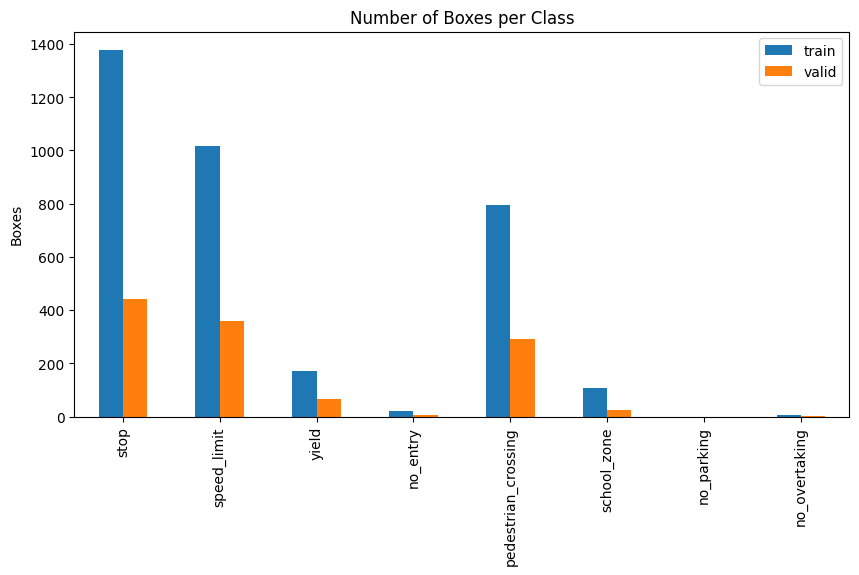

In [13]:
print(f'Training images: {len(os.listdir(DATA_DIR + "/train/images"))}')
print(f'Validation images: {len(os.listdir(DATA_DIR + "/valid/images"))}')

counts = pd.DataFrame(0, index=our_classes, columns=['train', 'valid'])
for split in ['train', 'valid']:
    for label_file in glob.glob(f'{DATA_DIR}/{split}/labels/*.txt'):
        for line in open(label_file).read().splitlines():
            counts.loc[our_classes[int(line.split()[0])], split] += 1

print(counts)

counts.plot(kind='bar', figsize=(10,5))
plt.title('Number of Boxes per Class')
plt.ylabel('Boxes')
plt.show()

[FILL IN!!: which classes have a lot of boxes and which have very few]

Training images with their boxes drawn on to make sure the labels look right.

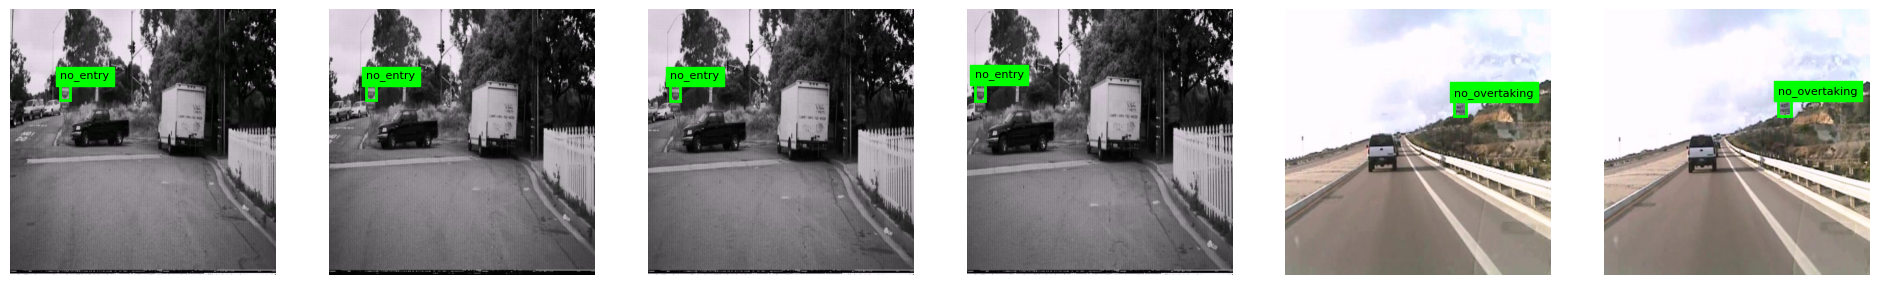

In [14]:
def show_examples(split, n=6):
    image_files = sorted(glob.glob(f'{DATA_DIR}/{split}/images/*'))[:n]
    if len(image_files) == 0:
        print('[PHOTO PLACEHOLDER] no images in', split, 'yet')
        return

    plt.figure(figsize=(4*len(image_files), 4))
    for i in range(len(image_files)):
        image = Image.open(image_files[i])
        width, height = image.size
        ax = plt.subplot(1, len(image_files), i+1)
        ax.imshow(image)

        file_name = os.path.splitext(os.path.basename(image_files[i]))[0]
        for line in open(f'{DATA_DIR}/{split}/labels/{file_name}.txt').read().splitlines():
            c, x, y, w, h = line.split()
            # yolo boxes are centre x, centre y, width, height as fractions of the image
            w = float(w) * width
            h = float(h) * height
            x = float(x) * width - w/2
            y = float(y) * height - h/2
            ax.add_patch(patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='lime', facecolor='none'))
            ax.text(x, y-5, our_classes[int(c)], color='black', backgroundcolor='lime', fontsize=8)
        ax.axis('off')
    plt.show()

show_examples('train')

## The Baseline Model
Fine-tuneing `yolo11n.pt`, which is YOLO already trained on the COCO dataset (it can already find stop signs).

**Before running: Runtime > Change runtime type > T4 GPU**

### Choice of Hyperparameters
- **Image size (imgsz):** what size the images get shrunk to before going into the model. Bigger keeps more detail for small signs that are far away, but it's slower.
- **Epochs:** how many times the model goes through all the training images.
- **Learning rate (lr0):** how big of a change the model makes to its weights each step.
- **Batch size:** how many images go through at once. We keep it at 16 for every run.
- **Optimizer:** we set it to SGD. If we leave it on 'auto', YOLO picks its own learning rate and ignores lr0, which would make the learning rate experiments useless.

We keep random seed at 42 so the runs can be compared fairly.

In [ ]:
baseline = {'epochs': 50, 'imgsz': 640, 'lr0': 0.01, 'batch': 16, 'optimizer': 'SGD', 'seed': 42}

model = YOLO('yolo11n.pt')
model.train(data=DATA_YAML, project=RUNS, name='baseline', exist_ok=True, **baseline)

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/traffic_signs/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize=False, op

Now load the best weights from training and check them on the validation set:

In [ ]:
model = YOLO(RUNS + '/baseline/weights/best.pt')
val_results = model.val(data=DATA_YAML, split='val', project=RUNS, name='baseline_val', exist_ok=True)

print(f'Baseline model\'s mAP50 on validation set is {100*val_results.box.map50:.2f}%')
print(f'Baseline model\'s mAP50-95 on validation set is {100*val_results.box.map:.2f}%')
print(f'Baseline model\'s precision on validation set is {100*val_results.box.mp:.2f}%')
print(f'Baseline model\'s recall on validation set is {100*val_results.box.mr:.2f}%')

In [ ]:
# save the results to drive so we can compare all the runs later
row = {'run': 'baseline',
       'mAP50': val_results.box.map50,
       'mAP50-95': val_results.box.map,
       'precision': val_results.box.mp,
       'recall': val_results.box.mr}
row.update(baseline)
pd.DataFrame([row]).to_csv(RUNS + '/results_baseline.csv', index=False)

### The Loss Curve
YOLO saves the loss for every epoch in `results.csv`. Box loss is how far off the boxes are and class loss is how wrong the class guesses are.

If training loss keeps going down but validation loss goes back up, the model is overfitting (like the 99.83% training vs 73.61% test gap we got with the MLP). If both are still going down at the end, it probably needed more epochs.

In [ ]:
def plot_loss(run_name):
    results = pd.read_csv(f'{RUNS}/{run_name}/results.csv')
    results.columns = results.columns.str.strip()

    plt.figure(figsize=(16,6))
    plt.subplot(1,2,1)
    plt.plot(results['epoch'], results['train/box_loss'], label='Training')
    plt.plot(results['epoch'], results['val/box_loss'], label='Validation')
    plt.title('Box Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(results['epoch'], results['train/cls_loss'], label='Training')
    plt.plot(results['epoch'], results['val/cls_loss'], label='Validation')
    plt.title('Class Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.show()

plot_loss('baseline')

[FILL IN: is it overfitting, underfitting or about right?]

### The Confusion Matrix
The rows are the true classes and the columns are what the model predicted. The diagonal is correct predictions. Detection also has a **background** class:
- True sign, predicted background = the model missed the sign.
- True background, predicted a sign = the model drew a box where there's no sign.

In [ ]:
def plot_confusion_matrix(results):
    # yolo stores it as predicted x true, so flip it so the rows are the true classes
    conf_matrix = results.confusion_matrix.matrix.T
    labels = our_classes + ['background']

    confmatrix_df = pd.DataFrame(conf_matrix, index=labels, columns=labels)
    # each row divided by its total
    confmatrix_df_norm = confmatrix_df.div(confmatrix_df.sum(axis=1), axis=0).fillna(0)

    plt.figure(figsize=(22,8))
    sn.set(font_scale=1.1)
    plt.subplot(1,2,1)
    plt.title('Confusion Matrix')
    sn.heatmap(confmatrix_df, annot=True, fmt='g')
    plt.ylabel('True')
    plt.xlabel('Predicted')
    plt.subplot(1,2,2)
    plt.title('Normalized Confusion Matrix')
    sn.heatmap(confmatrix_df_norm, annot=True, fmt='.2f')
    plt.ylabel('True')
    plt.xlabel('Predicted')
    plt.show()

plot_confusion_matrix(val_results)

[FILL IN: which classes it gets right the most and which ones it mixes up]

### Precision, Recall, mAP
**Precision** is how many of the boxes the model drew were actually right. Low precision means a lot of false positives (boxes where there's no sign, or the wrong sign).

**Recall** is how many of the real signs the model found. Low recall means a lot of missed signs. For a car this is probably the worse mistake, since missing a stop sign is more dangerous than seeing one that isn't there.

**mAP50** is the average precision over all the classes, where a box counts as correct if it overlaps the real box by at least 50%. **mAP50-95** does the same thing at stricter overlaps (50% up to 95%) and averages them, so it also checks how tight the boxes are. We use mAP50-95 to pick the best run.

Here are the scores for each class:

In [ ]:
def class_scores(results):
    scores = pd.DataFrame()
    scores['class'] = [our_classes[i] for i in results.box.ap_class_index]
    scores['precision'] = results.box.p
    scores['recall'] = results.box.r
    scores['F1'] = results.box.f1
    scores['mAP50'] = results.box.ap50
    scores['mAP50-95'] = results.box.ap
    return scores

class_scores(val_results)

## Hyperparameter Tuning
Each of us changes only our own hyperparameter to 3 new values and keeps everything else the same as the baseline, so any change in the score is because of that one thing. The results get saved to Drive after every run so we can each run our own cells on our own Colab?

In [ ]:
def run_experiment(run_name, **changes):
    settings = baseline.copy()
    settings.update(changes)
    print(run_name, settings)

    model = YOLO('yolo11n.pt')
    model.train(data=DATA_YAML, project=RUNS, name=run_name, exist_ok=True, **settings)

    model = YOLO(f'{RUNS}/{run_name}/weights/best.pt')
    results = model.val(data=DATA_YAML, split='val', project=RUNS, name=run_name + '_val', exist_ok=True)
    print(f'{run_name} mAP50-95 on validation set is {100*results.box.map:.2f}%')

    row = {'run': run_name,
           'mAP50': results.box.map50,
           'mAP50-95': results.box.map,
           'precision': results.box.mp,
           'recall': results.box.mr}
    row.update(settings)
    pd.DataFrame([row]).to_csv(f'{RUNS}/results_{run_name}.csv', index=False)


def compare_runs(run_names):
    table = pd.concat([pd.read_csv(f'{RUNS}/results_{name}.csv') for name in run_names])
    table.plot(x='run', y=['mAP50', 'mAP50-95'], kind='bar', figsize=(10,5))
    plt.title('Validation Scores')
    plt.ylabel('Score')
    plt.xticks(rotation=0)
    plt.show()
    return table

### Manroop: Image Size (baseline 640)

In [ ]:
run_experiment('manroop_imgsz_320', imgsz=320)
run_experiment('manroop_imgsz_480', imgsz=480)
run_experiment('manroop_imgsz_960', imgsz=960)

compare_runs(['baseline', 'manroop_imgsz_320', 'manroop_imgsz_480', 'manroop_imgsz_960'])

[FILL IN: Manroop's results compared to the baseline]

### Sean: Epochs (baseline 50)

In [ ]:
run_experiment('sean_epochs_25', epochs=25)
run_experiment('sean_epochs_75', epochs=75)
run_experiment('sean_epochs_100', epochs=100)

compare_runs(['baseline', 'sean_epochs_25', 'sean_epochs_75', 'sean_epochs_100'])

[FILL IN: Sean's results compared to the baseline]

### Vanshdeep: Learning Rate (baseline 0.01)

In [ ]:
run_experiment('vanshdeep_lr_0.001', lr0=0.001)
run_experiment('vanshdeep_lr_0.005', lr0=0.005)
run_experiment('vanshdeep_lr_0.02', lr0=0.02)

compare_runs(['baseline', 'vanshdeep_lr_0.001', 'vanshdeep_lr_0.005', 'vanshdeep_lr_0.02'])

[FILL IN: Vanshdeep's results compared to the baseline]

### Comparing Every Run
We will pick the best run by the validation score, not our photos. If we picked using our photos we would basically be tuning on the test set, and then the test score wouldn't mean anything.

In [ ]:
all_results = pd.concat([pd.read_csv(f) for f in glob.glob(RUNS + '/results_*.csv')])
all_results = all_results.sort_values('mAP50-95', ascending=False)
print(all_results)

best_run = all_results['run'].iloc[0]
print(f'\nBest run on validation set: {best_run}')

## Final Model
[FILL INN] Put the best value from each person's experiments here. If the combined model isn't better than the best single run, we keep the single run and explain why in the report.

In [ ]:
run_experiment('final_combo', imgsz=640, epochs=50, lr0=0.01)   # <- change these to the best values

In [ ]:
# change this to 'final_combo' if that one ends up best
final_run = best_run

final_model = YOLO(f'{RUNS}/{final_run}/weights/best.pt')
final_val = final_model.val(data=DATA_YAML, split='val', project=RUNS, name='final_val', exist_ok=True)

plot_loss(final_run)
plot_confusion_matrix(final_val)
class_scores(final_val)

In [ ]:
# save a copy of the final weights to drive
shutil.copy(f'{RUNS}/{final_run}/weights/best.pt', PROJECT + '/final_model.pt')

## Setting up for Our Photos
**[PHOTO PLACEHOLDER]** Each of us takes 30 photos, about 4 to 5 per class. Some should be in bad lighting or rain. Take them from the sidewalk or as a passenger.

**File names:** `name_class_number_condition.jpg`, for example `manroop_stop_01_day.jpg` or `sean_yield_03_rain.jpg`. The condition is `day`, `dark` or `rain`.

**Labeling in Label Studio:**
1. New project, Labeling Setup, "Object Detection with Bounding Boxes", then paste this into the Code tab so we all have the same labels:
```
<View>
  <Image name="image" value="$image"/>
  <RectangleLabels name="label" toName="image">
    <Label value="stop"/>
    <Label value="speed_limit"/>
    <Label value="yield"/>
    <Label value="no_entry"/>
    <Label value="pedestrian_crossing"/>
    <Label value="school_zone"/>
    <Label value="no_parking"/>
    <Label value="no_overtaking"/>
  </RectangleLabels>
</View>
```
2. Draw a tight box around every one of our 8 signs in the photo, even small or partly hidden ones. Don't box other signs.
3. Export as **YOLO**, unzip it and put it in `IAT 360 Computer Vision Project/own_photos/yourname/` (it should have `images`, `labels` and `classes.txt`).

Label Studio numbers the classes in its own order, so we use `classes.txt` to match them to our classes by name.

In [ ]:
members = ['manroop', 'sean', 'vanshdeep']
own_photos = []

for person in members:
    folder = f'{PROJECT}/own_photos/{person}'
    if not os.path.exists(folder + '/classes.txt'):
        print(f'[PHOTO PLACEHOLDER] no photos from {person} yet')
        continue

    ls_classes = open(folder + '/classes.txt').read().splitlines()
    for image_file in glob.glob(folder + '/images/*'):
        file_name = os.path.splitext(os.path.basename(image_file))[0]
        new_lines = []
        for line in open(f'{folder}/labels/{file_name}.txt').read().splitlines():
            parts = line.split()
            # change label studio's class number to ours
            new_class = our_classes.index(ls_classes[int(parts[0])])
            new_lines.append(str(new_class) + ' ' + ' '.join(parts[1:]))

        shutil.copy(image_file, DATA_DIR + '/test/images')
        with open(f'{DATA_DIR}/test/labels/{file_name}.txt', 'w') as f:
            f.write('\n'.join(new_lines))
        own_photos.append({'file': file_name, 'person': person, 'condition': file_name.split('_')[-1]})

own_photos = pd.DataFrame(own_photos)
print(f'Our photos: {len(own_photos)}')

In [ ]:
if len(own_photos) == 0:
    print('[PHOTO PLACEHOLDER] no photos yet')
else:
    # photos per person and condition
    print(pd.crosstab(own_photos['person'], own_photos['condition']))

    # boxes per class in our photos
    test_counts = pd.Series(0, index=our_classes)
    for label_file in glob.glob(DATA_DIR + '/test/labels/*.txt'):
        for line in open(label_file).read().splitlines():
            test_counts[our_classes[int(line.split()[0])]] += 1
    print(test_counts)

    show_examples('test')

## Testing on Our Photos
After hyperparameter tuning, we check the final model on our photos. Up to this point the model has not seen them at all. We also run the baseline on them to see if the tuning helped.

In [ ]:
if len(own_photos) == 0:
    print('[PHOTO PLACEHOLDER] no photos yet')
else:
    baseline_model = YOLO(RUNS + '/baseline/weights/best.pt')
    baseline_test = baseline_model.val(data=DATA_YAML, split='test', project=RUNS, name='baseline_test', exist_ok=True)
    test_results = final_model.val(data=DATA_YAML, split='test', project=RUNS, name='final_test', exist_ok=True)

    print(f'Baseline model\'s mAP50-95 on our photos is {100*baseline_test.box.map:.2f}%')
    print(f'Final model\'s mAP50 on our photos is {100*test_results.box.map50:.2f}%')
    print(f'Final model\'s mAP50-95 on our photos is {100*test_results.box.map:.2f}%')
    print(f'Final model\'s precision on our photos is {100*test_results.box.mp:.2f}%')
    print(f'Final model\'s recall on our photos is {100*test_results.box.mr:.2f}%')

    plot_confusion_matrix(test_results)

In [ ]:
if len(own_photos) == 0:
    print('[PHOTO PLACEHOLDER] no photos yet')
else:
    print(class_scores(test_results))

Let's compare what the model found in each photo against what is really in it:

In [ ]:
matches = []
for i in range(len(own_photos)):
    file_name = own_photos['file'].iloc[i]
    image_file = glob.glob(f'{DATA_DIR}/test/images/{file_name}.*')[0]

    true = []
    for line in open(f'{DATA_DIR}/test/labels/{file_name}.txt').read().splitlines():
        true.append(our_classes[int(line.split()[0])])

    result = final_model.predict(image_file, conf=0.25, verbose=False)[0]
    pred = []
    for c in result.boxes.cls:
        pred.append(our_classes[int(c)])

    # just compare which signs are in the photo
    true = sorted(set(true))
    pred = sorted(set(pred))
    matches.append(true == pred)
    print(f"Photo {i}: Predicted = {pred}, True = {true} | Match: {true == pred}")

if len(own_photos) == 0:
    print('[PHOTO PLACEHOLDER] no photos yet')
else:
    own_photos['match'] = matches
    print(f'\nPhotos fully correct: {sum(matches)} out of {len(matches)}')
    print(own_photos.groupby('condition')['match'].mean())

[FILL IN: is it worse in the dark or rain? which signs does it miss?]

Here we can put some of the photos it got wrong, with the model's boxes drawn on (good for the report):

In [ ]:
if len(own_photos) == 0:
    print('[PHOTO PLACEHOLDER] no photos yet')
else:
    wrong = own_photos[own_photos['match'] == False]['file'].tolist()[:6]
    plt.figure(figsize=(4*6, 4))
    for i in range(len(wrong)):
        image_file = glob.glob(f'{DATA_DIR}/test/images/{wrong[i]}.*')[0]
        result = final_model.predict(image_file, conf=0.25, verbose=False)[0]
        plt.subplot(1, 6, i+1)
        plt.imshow(result.plot()[:, :, ::-1])   # plot() gives BGR so flip it to RGB
        plt.title(wrong[i], fontsize=8)
        plt.axis('off')
    plt.show()

## Conclusion
[FILL IN after the results are in: best model, why it did best, where it struggles (dark, rain, small signs, US vs Canadian signs), and ethical concerns]